In [1]:
!pip install pandas numpy scikit-learn matplotlib joblib rich


In [2]:
# === MASTER SETUP 
from pathlib import Path
from dataclasses import dataclass

import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix,
    roc_curve, roc_auc_score,
    precision_recall_curve, average_precision_score,
)
from sklearn.inspection import permutation_importance
from joblib import dump, load
import matplotlib.pyplot as plt

# ---- Paths ----
ROOT = Path(".")
DATA_DIR = ROOT / "data"
ART = ROOT / "artifacts"
ART.mkdir(exist_ok=True)

# ---- Column names ----
COLS = [
    'duration','protocol_type','service','flag','src_bytes','dst_bytes',
    'land','wrong_fragment','urgent','hot','num_failed_logins','logged_in',
    'num_compromised','root_shell','su_attempted','num_root',
    'num_file_creations','num_shells','num_access_files','num_outbound_cmds',
    'is_host_login','is_guest_login','count','srv_count','serror_rate',
    'srv_serror_rate','rerror_rate','srv_rerror_rate','same_srv_rate',
    'diff_srv_rate','srv_diff_host_rate','dst_host_count',
    'dst_host_srv_count','dst_host_same_srv_rate','dst_host_diff_srv_rate',
    'dst_host_same_src_port_rate','dst_host_srv_diff_host_rate',
    'dst_host_serror_rate','dst_host_srv_serror_rate','dst_host_rerror_rate',
    'dst_host_srv_rerror_rate','label','difficulty'
]

# ---- Load data once ----
train_path = DATA_DIR / "KDDTrain+.txt"   # change name if needed
test_path  = DATA_DIR / "KDDTest+.txt"

df_train = pd.read_csv(train_path, names=COLS)
df_test  = pd.read_csv(test_path,  names=COLS)

# Binary labels
y_train_bin = (df_train["label"] != "normal").astype(int).values
y_test_bin  = (df_test["label"]  != "normal").astype(int).values

# Features (41 original columns)
X_train = df_train.drop(columns=["label", "difficulty"])
X_test  = df_test.drop(columns=["label", "difficulty"])

# Convenience alias for some cells that used y_test
y_test = y_test_bin

# ---- Preprocessor  ----
numeric_features = X_train.select_dtypes(include=[np.number]).columns.tolist()
categorical_features = [c for c in X_train.columns if c not in numeric_features]

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("num", StandardScaler(), numeric_features),
    ]
)

# ---- Random Forest pipeline ----
rf_pipe = Pipeline([
    ("prep", preprocessor),
    ("clf", RandomForestClassifier(
        n_estimators=200,
        max_depth=None,
        n_jobs=-1,
        class_weight="balanced_subsample",
        random_state=42,
    )),
])

# ---- ANN / MLP pipeline ----
ann_pipe = Pipeline([
    ("prep", preprocessor),
    ("clf", MLPClassifier(
        hidden_layer_sizes=(128, 64),
        activation="relu",
        solver="adam",
        batch_size=256,
        learning_rate_init=1e-3,
        max_iter=30,
        early_stopping=True,
        random_state=42,
        verbose=False,
    )),
])

print("MASTER SETUP COMPLETE")
print("Train/Test shapes:", X_train.shape, X_test.shape)


MASTER SETUP COMPLETE
Train/Test shapes: (125973, 41) (22544, 41)


In [3]:

import os
import pathlib
import warnings
warnings.filterwarnings("ignore")

from dataclasses import dataclass
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from joblib import dump
from sklearn.utils.class_weight import compute_sample_weight

# Optional: Rich print (for coloured terminal text)
try:
    from rich import print as rprint
except Exception:
    def rprint(*args, **kwargs):
        print(*args, **kwargs)

#
# ### 1) File Paths and Column Names

# %%
DATA_DIR = pathlib.Path("./data")
TRAIN_FILE = DATA_DIR / "KDDTrain+.txt"
TEST_FILE = DATA_DIR / "KDDTest+.txt"

SAVE_DIR = pathlib.Path("./artifacts")
SAVE_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

# NSL-KDD dataset column names
COLS = [
    'duration', 'protocol_type', 'service', 'flag', 'src_bytes', 'dst_bytes', 'land',
    'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'logged_in', 'num_compromised',
    'root_shell', 'su_attempted', 'num_root', 'num_file_creations', 'num_shells',
    'num_access_files', 'num_outbound_cmds', 'is_host_login', 'is_guest_login',
    'count', 'srv_count', 'serror_rate', 'srv_serror_rate', 'rerror_rate',
    'srv_rerror_rate', 'same_srv_rate', 'diff_srv_rate', 'srv_diff_host_rate',
    'dst_host_count', 'dst_host_srv_count', 'dst_host_same_srv_rate',
    'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate',
    'dst_host_srv_diff_host_rate', 'dst_host_serror_rate', 'dst_host_srv_serror_rate',
    'dst_host_rerror_rate', 'dst_host_srv_rerror_rate', 'label', 'difficulty'
]

CATEGORICAL = ['protocol_type', 'service', 'flag']
NUMERIC = [c for c in COLS if c not in CATEGORICAL + ['label', 'difficulty']]


#  2) Load and Prepare Data


def load_nsl_kdd(train_path: pathlib.Path, test_path: pathlib.Path):
    if not train_path.exists() or not test_path.exists():
        raise FileNotFoundError(
            f"Missing dataset files. Please ensure {train_path} and {test_path} exist."
        )
    df_train = pd.read_csv(train_path, names=COLS)
    df_test = pd.read_csv(test_path, names=COLS)
    return df_train, df_test


def make_binary_labels(df: pd.DataFrame) -> pd.Series:
    """Binary labels: normal -> 0, attack -> 1"""
    return (df['label'] != 'normal').astype(int)



rprint("[bold cyan]Loading NSL-KDD dataset...[/bold cyan]")
df_train, df_test = load_nsl_kdd(TRAIN_FILE, TEST_FILE)
rprint(f"Train shape: {df_train.shape}, Test shape: {df_test.shape}")
df_train.head()


y_train = make_binary_labels(df_train).values
y_test = make_binary_labels(df_test).values

X_train = df_train.drop(columns=['label', 'difficulty'])
X_test = df_test.drop(columns=['label', 'difficulty'])


#3) Preprocessing


from sklearn.preprocessing import FunctionTransformer

def build_preprocessor(scale_numeric: bool) -> ColumnTransformer:
    transformers = []
    transformers.append(("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL))
    
    if scale_numeric:
        transformers.append(("num", StandardScaler(), NUMERIC))
    else:
        transformers.append(("num", FunctionTransformer(lambda x: x), NUMERIC))
    
    return ColumnTransformer(transformers, remainder='drop', verbose_feature_names_out=False)

# 
# 4) Random Forest Model

rf_pipe = Pipeline([
    ("prep", build_preprocessor(scale_numeric=True)),
    ("clf", RandomForestClassifier(
        n_estimators=300,
        n_jobs=-1,
        random_state=RANDOM_STATE,
        class_weight="balanced",      #  handles class imbalance
    )),
])

rprint("[bold]Training Random Forest...[/bold]")
rf_pipe.fit(X_train, y_train)
y_pred_rf = rf_pipe.predict(X_test)


def evaluate(name, y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average='binary', zero_division=0)
    cm = confusion_matrix(y_true, y_pred)
    rprint(f"\n[bold]{name}[/bold]")
    rprint(f"Accuracy : {acc:.4f}")
    rprint(f"Precision: {prec:.4f}")
    rprint(f"Recall   : {rec:.4f}")
    rprint(f"F1-score : {f1:.4f}")
    rprint("Confusion Matrix:\n", cm)
    rprint("\nClassification Report:\n" + classification_report(
        y_true, y_pred, target_names=['normal(0)', 'attack(1)']))

# 
evaluate("Random Forest (Binary)", y_test, y_pred_rf)
dump(rf_pipe, SAVE_DIR / "nslkdd_rf_pipeline.joblib")
rprint("[green]Random Forest model saved in artifacts/[/green]")


# ### 5) Artificial Neural Network (ANN)


ann_pipe = Pipeline([
    ("prep", build_preprocessor(scale_numeric=True)),
    ("clf", MLPClassifier(
        hidden_layer_sizes=(128, 64),
        activation='relu',
        solver='adam',
        batch_size=256,
        learning_rate_init=1e-3,
        max_iter=30,
        early_stopping=True,
        random_state=RANDOM_STATE,
        verbose=False
    )),
])

rprint("\n[bold]Training ANN (MLPClassifier)...[/bold]")
ann_pipe.fit(X_train, y_train)
y_pred_ann = ann_pipe.predict(X_test)

evaluate("ANN / MLP (Binary)", y_test, y_pred_ann)
dump(ann_pipe, SAVE_DIR / "nslkdd_ann_pipeline.joblib")
rprint("[green]ANN model saved in artifacts/[/green]")


# ### 6) Comparison Summary


summary = pd.DataFrame([
    {"Model": "Random Forest", "Accuracy": accuracy_score(y_test, y_pred_rf)},
    {"Model": "ANN / MLP", "Accuracy": accuracy_score(y_test, y_pred_ann)},
])
rprint("\n[bold cyan]Model Comparison Summary[/bold cyan]")
rprint(summary)

rprint("\nNext Steps:\n"
       "1. Hyperparameter tuning (GridSearchCV/RandomizedSearchCV).\n"
       "2. Plot ROC/Precision-Recall curves.\n"
       "3. Add SHAP explainability.\n"
       "4. Extend to 5-class classification.\n"
       "5. Build AI-agent wrapper (Capture → Analysis → Manager).")


Loading NSL-KDD dataset...

Train shape: (125973, 43), Test shape: (22544, 43)

Training Random Forest...

Random Forest (Binary)

Accuracy : 0.7663

Precision: 0.9677

... (13 outputs left out)

ANN model saved in artifacts/

Model Comparison Summary

Model  Accuracy
0  Random Forest  0.766279
1      ANN / MLP  0.805225

Next Steps:
1. Hyperparameter tuning (GridSearchCV/RandomizedSearchCV).
2. Plot ROC/Precision-Recall curves.
3. Add SHAP explainability.
4. Extend to 5-class classification.
5. Build AI-agent wrapper (Capture → Analysis → Manager).

In [4]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

def build_preprocessor(scale_numeric: bool) -> ColumnTransformer:
    # cat
    cat = ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL)
    num = ("num", StandardScaler() if scale_numeric else "passthrough", NUMERIC)
    return ColumnTransformer([cat, num], remainder="drop", verbose_feature_names_out=False)


In [5]:
# Rebuild RF
rf_pipe = Pipeline([
    ("prep", build_preprocessor(scale_numeric=False)),
    ("clf", RandomForestClassifier(
        n_estimators=300,
        n_jobs=-1,
        random_state=RANDOM_STATE,
        class_weight="balanced_subsample"
    )),
])

rprint("[bold]Re-training Random Forest...[/bold]")
rf_pipe.fit(X_train, y_train)
y_pred_rf = rf_pipe.predict(X_test)
evaluate("Random Forest (Binary)", y_test, y_pred_rf)

from joblib import dump
dump(rf_pipe, SAVE_DIR / "nslkdd_rf_pipeline.joblib")
rprint("[green]Saved RF model → artifacts/nslkdd_rf_pipeline.joblib[/green]")


Re-training Random Forest...

Random Forest (Binary)

Accuracy : 0.7726

Precision: 0.9679

Recall   : 0.6211

F1-score : 0.7567

Confusion Matrix:
 [[9447  264]
 [4862 7971]]

Classification Report:
              precision    recall  f1-score   support

   normal(0)       0.66      0.97      0.79      9711
   attack(1)       0.97      0.62      0.76     12833

    accuracy                           0.77     22544
   macro avg       0.81      0.80      0.77     22544
weighted avg       0.84      0.77      0.77     22544

Saved RF model → artifacts/nslkdd_rf_pipeline.joblib

In [6]:
# Save + standard name
dump(rf_pipe, ART / "nslkdd_rf_pipeline.joblib")
rf = rf_pipe
print("Saved RF model as artifacts/nslkdd_rf_pipeline.joblib")


Saved RF model as artifacts/nslkdd_rf_pipeline.joblib


In [7]:
# Rebuild ANN pipeline
ann_pipe = Pipeline([
    ("prep", build_preprocessor(scale_numeric=True)),
    ("clf", MLPClassifier(
        hidden_layer_sizes=(128, 64),
        activation='relu',
        solver='adam',
        batch_size=256,
        learning_rate_init=1e-3,
        max_iter=30,
        early_stopping=True,
        random_state=RANDOM_STATE,
        verbose=False
    )),
])

print("[bold]Training ANN (MLPClassifier) with balanced sample weights...[/bold]")

# 1) compute sample weights for y_train
ann_sample_w = compute_sample_weight(class_weight="balanced", y=y_train)

# 2) fit ANN using weights 
ann_pipe.fit(X_train, y_train, clf__sample_weight=ann_sample_w)

# 3) evaluate as usual
y_pred_ann = ann_pipe.predict(X_test)
evaluate("ANN / MLP (Binary, balanced)", y_test, y_pred_ann)


[bold]Training ANN (MLPClassifier) with balanced sample weights...[/bold]


ANN / MLP (Binary, balanced)

Accuracy : 0.7834

Precision: 0.9320

Recall   : 0.6684

F1-score : 0.7785

Confusion Matrix:
 [[9085  626]
 [4256 8577]]

Classification Report:
              precision    recall  f1-score   support

   normal(0)       0.68      0.94      0.79      9711
   attack(1)       0.93      0.67      0.78     12833

    accuracy                           0.78     22544
   macro avg       0.81      0.80      0.78     22544
weighted avg       0.82      0.78      0.78     22544

In [8]:
dump(ann_pipe, ART / "nslkdd_ann_pipeline.joblib")
ann = ann_pipe
print("Saved ANN model as artifacts/nslkdd_ann_pipeline.joblib")


Saved ANN model as artifacts/nslkdd_ann_pipeline.joblib


In [9]:
import os, glob
glob.glob("artifacts/*.joblib")


['artifacts\\nslkdd_ann_calibrated.joblib',
 'artifacts\\nslkdd_ann_pipeline.joblib',
 'artifacts\\nslkdd_rf_calibrated.joblib',
 'artifacts\\nslkdd_rf_pipeline.joblib']

In [10]:
# Reload models safely 
rf = load(ART / "nslkdd_rf_pipeline.joblib")
ann = load(ART / "nslkdd_ann_pipeline.joblib")

print("Models loaded for analysis:")
print("  RF :", type(rf))
print("  ANN:", type(ann))


Models loaded for analysis:
  RF : <class 'sklearn.pipeline.Pipeline'>
  ANN: <class 'sklearn.pipeline.Pipeline'>


## Phase 3 — AI Agent Simulation (Capture → Analysis → Manager)


In [11]:
from joblib import load
import pandas as pd
import numpy as np
from pathlib import Path

# Paths
ARTIFACTS = Path("./artifacts")
DATA_DIR  = Path("./data")

# Choose model: "ann" or "rf"
which_model = "rf"   

MODEL_PATH = ARTIFACTS / ("nslkdd_ann_pipeline.joblib" if which_model=="ann"
                           else "nslkdd_rf_pipeline.joblib")
pipe = load(MODEL_PATH)
print(f"Loaded model: {MODEL_PATH.name}")

# Reload test set
COLS = [
    'duration','protocol_type','service','flag','src_bytes','dst_bytes','land','wrong_fragment','urgent',
    'hot','num_failed_logins','logged_in','num_compromised','root_shell','su_attempted','num_root',
    'num_file_creations','num_shells','num_access_files','num_outbound_cmds','is_host_login','is_guest_login',
    'count','srv_count','serror_rate','srv_serror_rate','rerror_rate','srv_rerror_rate','same_srv_rate',
    'diff_srv_rate','srv_diff_host_rate','dst_host_count','dst_host_srv_count','dst_host_same_srv_rate',
    'dst_host_diff_srv_rate','dst_host_same_src_port_rate','dst_host_srv_diff_host_rate','dst_host_serror_rate',
    'dst_host_srv_serror_rate','dst_host_rerror_rate','dst_host_srv_rerror_rate','label','difficulty'
]
df_test = pd.read_csv(DATA_DIR/"KDDTest+.txt", names=COLS)
X_test  = df_test.drop(columns=["label","difficulty"])
y_test_bin = (df_test["label"]!="normal").astype(int).values  # 0=normal, 1=attack
print("Test stream ready:", X_test.shape)


Loaded model: nslkdd_rf_pipeline.joblib
Test stream ready: (22544, 41)


In [12]:
import time
from dataclasses import dataclass

ATTACK_THRESHOLD = 0.50  # probability threshold for class 1 (attack)

@dataclass
class Packet:
    index: int
    features: pd.Series
    true_label: int | None = None  # optional (for offline evaluation)

class CaptureAgent:
    """Reads rows from a dataframe in small batches to simulate live capture."""
    def __init__(self, df_features: pd.DataFrame, y_true: np.ndarray | None = None):
        self.df = df_features.reset_index(drop=True)
        self.y  = y_true

    def stream(self, batch_size=100):
        n = len(self.df)
        for start in range(0, n, batch_size):
            batch = []
            end = min(start+batch_size, n)
            for i in range(start, end):
                y_i = int(self.y[i]) if self.y is not None else None
                batch.append(Packet(index=i, features=self.df.iloc[i], true_label=y_i))
            yield batch
            # time.sleep(0.1)  # uncomment to simulate delay

class AnalysisAgent:
    """Uses the trained pipeline to score packets."""
    def __init__(self, pipeline, threshold=0.5):
        self.pipeline = pipeline
        self.threshold = threshold

    def score_batch(self, packets: list[Packet]):
        X = pd.DataFrame([p.features for p in packets])
        proba = self.pipeline.predict_proba(X)[:, 1]
        preds = (proba >= self.threshold).astype(int)
        results = []
        for p, pr, pd_ in zip(packets, proba, preds):
            results.append({
                "index": p.index,
                "pred": int(pd_),
                "prob_attack": float(pr),
                "true": p.true_label
            })
        return results

class ManagerAgent:
    """Aggregates results and raises simple alerts; can also write a CSV report."""
    def __init__(self):
        self.alerts = []
        self.all_results = []

    def handle_results(self, results, alert_threshold=0.90):
        self.all_results.extend(results)
        for r in results:
            if r["prob_attack"] >= alert_threshold:
                self.alerts.append(r)

    def report(self, to_csv_path: str | None = None):
        df = pd.DataFrame(self.all_results)
        print(f"\n--- Manager Summary ---")
        print(f"Total packets processed: {len(df)}")
        if "true" in df.columns and df['true'].notna().any():
            acc = (df["pred"] == df["true"]).mean()
            print(f"Offline accuracy (on streamed subset): {acc:.4f}")
        print(f"High-probability alerts (>=0.90): {len(self.alerts)}")
        if self.alerts[:5]:
            print("Top alerts (first 5):")
            print(pd.DataFrame(self.alerts).head())
        if to_csv_path:
            df.to_csv(to_csv_path, index=False)
            print(f"Saved detailed results → {to_csv_path}")


In [13]:
cap = CaptureAgent(X_test, y_test_bin)      # test set as "live stream"
ana = AnalysisAgent(rf, threshold=ATTACK_THRESHOLD)
mgr = ManagerAgent()

# Process a few batches
num_batches = 3           
batch_size  = 500

for b, batch in enumerate(cap.stream(batch_size=batch_size), start=1):
    results = ana.score_batch(batch)
    mgr.handle_results(results, alert_threshold=0.90)
    print(f"Processed batch {b} (size={len(batch)})")
    if b >= num_batches:
        break

mgr.report(to_csv_path="artifacts/stream_results_sample.csv")


Processed batch 1 (size=500)
Processed batch 2 (size=500)
Processed batch 3 (size=500)

--- Manager Summary ---
Total packets processed: 1500
Offline accuracy (on streamed subset): 0.7973
High-probability alerts (>=0.90): 479
Top alerts (first 5):
   index  pred  prob_attack  true
0      0     1     1.000000     1
1      1     1     1.000000     1
2      3     1     0.922327     1
3     12     1     1.000000     1
4     19     1     1.000000     1
Saved detailed results → artifacts/stream_results_sample.csv


In [14]:
import pandas as pd
pd.read_csv("artifacts/stream_results_sample.csv").head()


,index,pred,prob_attack,true
0,0,1,1.000000,1
1,1,1,1.000000,1
2,2,0,0.000000,0
3,3,1,0.922327,1
4,4,0,0.353333,1


In [15]:
from joblib import load
import pandas as pd
import numpy as np
from sklearn.metrics import roc_curve, auc, precision_recall_curve
import matplotlib.pyplot as plt
from pathlib import Path

# Paths
ARTIFACTS = Path("./artifacts")
DATA_DIR = Path("./data")

# Load data
COLS = [
    'duration','protocol_type','service','flag','src_bytes','dst_bytes','land','wrong_fragment','urgent',
    'hot','num_failed_logins','logged_in','num_compromised','root_shell','su_attempted','num_root',
    'num_file_creations','num_shells','num_access_files','num_outbound_cmds','is_host_login','is_guest_login',
    'count','srv_count','serror_rate','srv_serror_rate','rerror_rate','srv_rerror_rate','same_srv_rate',
    'diff_srv_rate','srv_diff_host_rate','dst_host_count','dst_host_srv_count','dst_host_same_srv_rate',
    'dst_host_diff_srv_rate','dst_host_same_src_port_rate','dst_host_srv_diff_host_rate','dst_host_serror_rate',
    'dst_host_srv_serror_rate','dst_host_rerror_rate','dst_host_srv_rerror_rate','label','difficulty'
]
df_test = pd.read_csv(DATA_DIR / "KDDTest+.txt", names=COLS)
X_test = df_test.drop(columns=["label", "difficulty"])
y_test_bin = (df_test["label"] != "normal").astype(int).values

# Load both models
rf = load(ARTIFACTS / "nslkdd_rf_pipeline.joblib")
ann = load(ARTIFACTS / "nslkdd_ann_pipeline.joblib")

print("✅ Models loaded successfully")


✅ Models loaded successfully


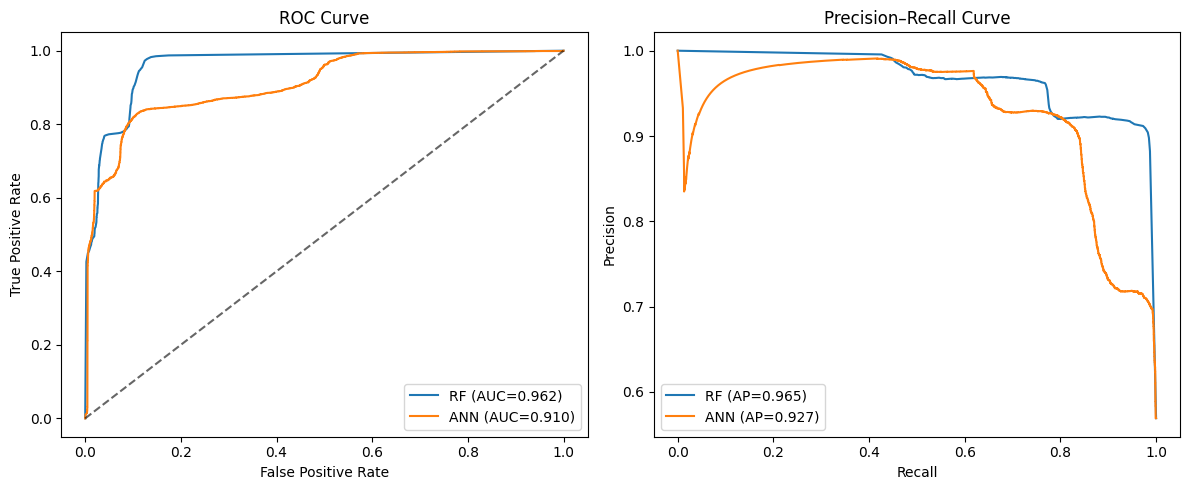

In [16]:
from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score,
)
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

# Where to save the figure
ARTIFACTS = Path("./artifacts")

# 1) Get probabilities for both models (class 1 = attack)
rf_probs  = rf.predict_proba(X_test)[:, 1]
ann_probs = ann.predict_proba(X_test)[:, 1]

# 2) ROC curves + AUC
fpr_rf,  tpr_rf,  _ = roc_curve(y_test_bin, rf_probs)
fpr_ann, tpr_ann, _ = roc_curve(y_test_bin, ann_probs)

rf_auc  = roc_auc_score(y_test_bin, rf_probs)
ann_auc = roc_auc_score(y_test_bin, ann_probs)

# 3) Precision–Recall curves + Average Precision (AP)
prec_rf,  rec_rf,  _ = precision_recall_curve(y_test_bin, rf_probs)
prec_ann, rec_ann, _ = precision_recall_curve(y_test_bin, ann_probs)

rf_ap  = average_precision_score(y_test_bin, rf_probs)
ann_ap = average_precision_score(y_test_bin, ann_probs)

# 4) Plot ROC + PR
plt.figure(figsize=(12, 5))

# --- ROC subplot ---
plt.subplot(1, 2, 1)
plt.plot(fpr_rf,  tpr_rf,  label=f"RF (AUC={rf_auc:.3f})")
plt.plot(fpr_ann, tpr_ann, label=f"ANN (AUC={ann_auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", alpha=0.6)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend(loc="lower right")

# --- Precision–Recall subplot ---
plt.subplot(1, 2, 2)
plt.plot(rec_rf,  prec_rf,  label=f"RF (AP={rf_ap:.3f})")
plt.plot(rec_ann, prec_ann, label=f"ANN (AP={ann_ap:.3f})")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve")
plt.legend(loc="lower left")

plt.tight_layout()

# Save to artifacts for report
plt.savefig(ARTIFACTS / "roc_pr_curves.png", dpi=300, bbox_inches="tight")
plt.show()



In [17]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt
import numpy as np

# Predictions
rf_pred = rf.predict(X_test)
ann_pred = ann.predict(X_test)

# Calculate metrics
metrics = {
    "Model": ["Random Forest", "ANN (MLP)"],
    "Accuracy": [
        accuracy_score(y_test_bin, rf_pred),
        accuracy_score(y_test_bin, ann_pred)
    ],
    "Precision": [
        precision_score(y_test_bin, rf_pred),
        precision_score(y_test_bin, ann_pred)
    ],
    "Recall": [
        recall_score(y_test_bin, rf_pred),
        recall_score(y_test_bin, ann_pred)
    ],
    "F1-score": [
        f1_score(y_test_bin, rf_pred),
        f1_score(y_test_bin, ann_pred)
    ]
}

import pandas as pd
df_metrics = pd.DataFrame(metrics)
df_metrics


,Model,Accuracy,Precision,Recall,F1-score
0,Random Forest,0.772622,0.967942,0.621133,0.756693
1,ANN (MLP),0.783446,0.931979,0.668355,0.778453


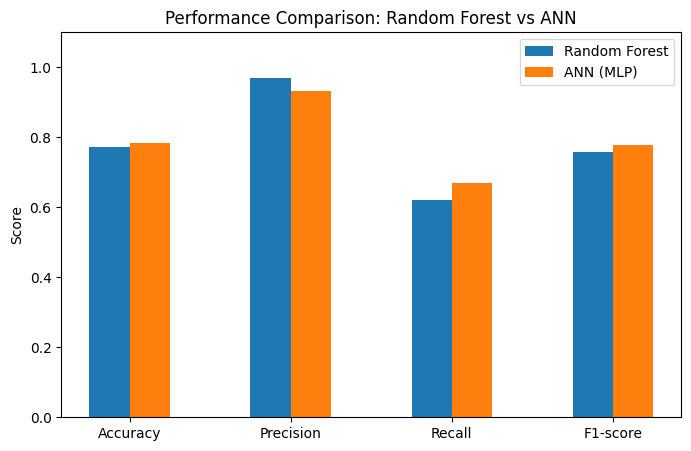

In [18]:
# Bar chart comparison
fig, ax = plt.subplots(figsize=(8,5))
width = 0.25
x = np.arange(4)  # Accuracy, Precision, Recall, F1

rf_vals = df_metrics.iloc[0,1:].values
ann_vals = df_metrics.iloc[1,1:].values

ax.bar(x - width/2, rf_vals, width, label="Random Forest")
ax.bar(x + width/2, ann_vals, width, label="ANN (MLP)")

ax.set_xticks(x)
ax.set_xticklabels(["Accuracy", "Precision", "Recall", "F1-score"])
ax.set_ylim(0, 1.1)
ax.set_ylabel("Score")
ax.set_title("Performance Comparison: Random Forest vs ANN")
ax.legend()
plt.show()


In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance

# Grab the trained RF pipeline (already loaded as `rf`)
prep = rf.named_steps["prep"]
clf  = rf.named_steps["clf"]

# get feature names after OneHotEncoder + numeric columns
try:
    feat_names = prep.get_feature_names_out()
except Exception:
    # fallback for very old sklearn
    cat_names = list(prep.transformers_[0][2])
    num_names = list(prep.transformers_[1][2])
    feat_names = np.array(cat_names + num_names)

len(feat_names), feat_names[:10]


(122,
 array(['protocol_type_icmp', 'protocol_type_tcp', 'protocol_type_udp',
        'service_IRC', 'service_X11', 'service_Z39_50', 'service_aol',
        'service_auth', 'service_bgp', 'service_courier'], dtype=object))

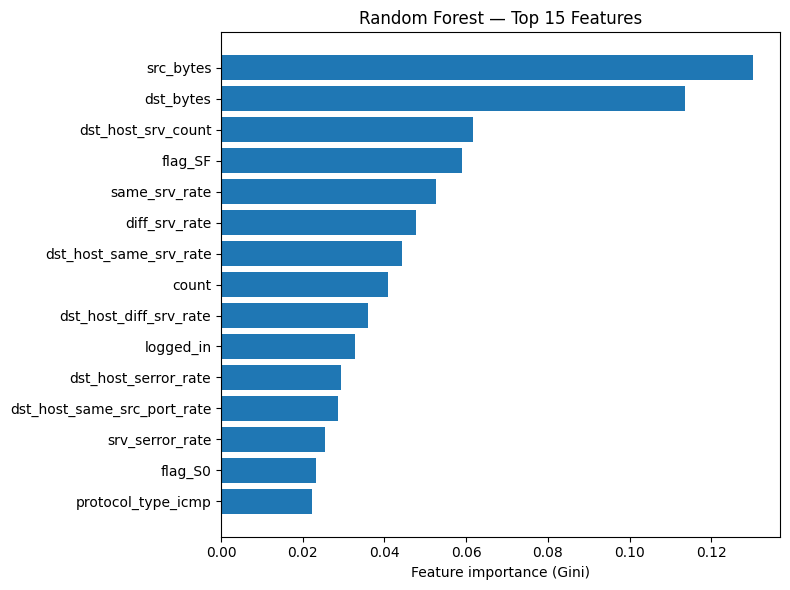

In [20]:
importances = clf.feature_importances_
order = np.argsort(importances)[::-1]
top_k = 15

plt.figure(figsize=(8,6))
plt.barh(range(top_k), importances[order][:top_k][::-1])
plt.yticks(range(top_k), feat_names[order][:top_k][::-1])
plt.xlabel("Feature importance (Gini)")
plt.title("Random Forest — Top 15 Features")
plt.tight_layout()
plt.show()


In [21]:
from sklearn.inspection import permutation_importance
import pandas as pd

# Use the raw feature names from X_test (41 original columns)
feat_names_perm = X_test.columns

# Permutation importance on the full pipeline (rf)
r = permutation_importance(
    rf,                 #  RF pipeline
    X_test,             # original test DataFrame (41 cols)
    y_test_bin,         # binary labels
    scoring="f1",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

# Build DataFrame
pi = pd.DataFrame({
    "feature": feat_names_perm,
    "importance_mean": r.importances_mean,
    "importance_std": r.importances_std
}).sort_values("importance_mean", ascending=False)

pi.head(20)


,feature,importance_mean,importance_std
4,src_bytes,0.057840,0.000246
3,flag,0.021443,0.000311
39,dst_host_rerror_rate,0.014195,0.000553
37,dst_host_serror_rate,0.011382,0.000426
29,diff_srv_rate,0.009891,0.000839
36,dst_host_srv_diff_host_rate,0.009817,0.000669
26,rerror_rate,0.009399,0.000536
32,dst_host_srv_count,0.008482,0.000952
11,logged_in,0.008134,0.000786
5,dst_bytes,0.007271,0.000845


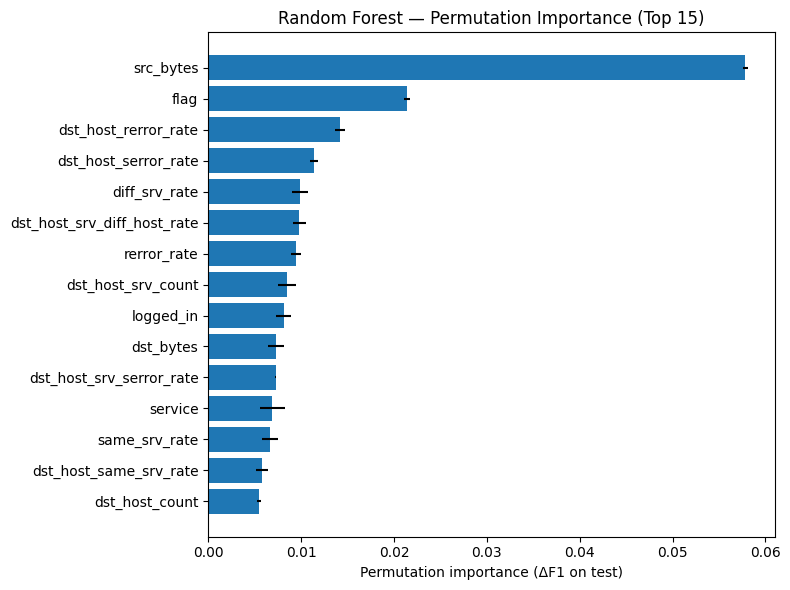

In [22]:
top = pi.head(15).iloc[::-1]  # reverse for nicer barh
plt.figure(figsize=(8,6))
plt.barh(top["feature"], top["importance_mean"], xerr=top["importance_std"])
plt.xlabel("Permutation importance (ΔF1 on test)")
plt.title("Random Forest — Permutation Importance (Top 15)")
plt.tight_layout()
plt.show()


In [23]:
plt.savefig("artifacts/rf_feature_importance.png", dpi=200, bbox_inches="tight")
# and
plt.savefig("artifacts/rf_permutation_importance.png", dpi=200, bbox_inches="tight")


<Figure size 640x480 with 0 Axes>

In [24]:
from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt

# Use the raw 41 feature names from X_test
feat_names_perm = X_test.columns

# Run permutation importance on the full pipeline (rf)
r = permutation_importance(
    rf, X_test, y_test_bin,
    scoring="f1", n_repeats=5, random_state=42, n_jobs=-1
)

# Build DataFrame
pi = pd.DataFrame({
    "feature": feat_names_perm,
    "importance_mean": r.importances_mean,
    "importance_std": r.importances_std
}).sort_values("importance_mean", ascending=False)

# Preview top 20
pi.head(20)


,feature,importance_mean,importance_std
4,src_bytes,0.057840,0.000246
3,flag,0.021443,0.000311
39,dst_host_rerror_rate,0.014195,0.000553
37,dst_host_serror_rate,0.011382,0.000426
29,diff_srv_rate,0.009891,0.000839
36,dst_host_srv_diff_host_rate,0.009817,0.000669
26,rerror_rate,0.009399,0.000536
32,dst_host_srv_count,0.008482,0.000952
11,logged_in,0.008134,0.000786
5,dst_bytes,0.007271,0.000845


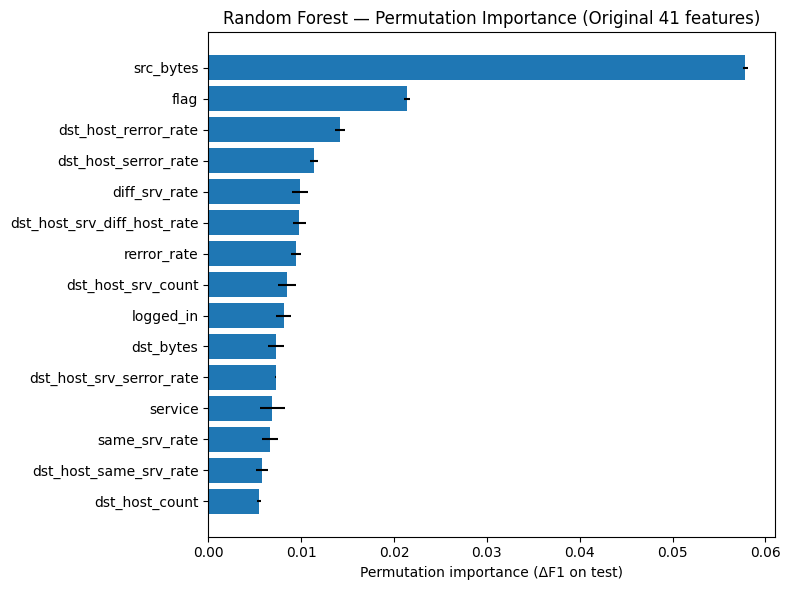

In [25]:
# Plot top 15 features
top = pi.head(15).iloc[::-1]
plt.figure(figsize=(8,6))
plt.barh(top["feature"], top["importance_mean"], xerr=top["importance_std"])
plt.xlabel("Permutation importance (ΔF1 on test)")
plt.title("Random Forest — Permutation Importance (Original 41 features)")
plt.tight_layout()
plt.show()


In [26]:
plt.savefig("artifacts/rf_permutation_importance.png", dpi=200, bbox_inches="tight")


<Figure size 640x480 with 0 Axes>

In [27]:

# import shap, numpy as np, pandas as pd, matplotlib.pyplot as plt

# # Use the trained RF *pipeline* loaded as `rf`
# prep = rf.named_steps["prep"]
# clf  = rf.named_steps["clf"]

# # Transform test set to the encoded numeric matrix used by RF
# X_test_tx = prep.transform(X_test)                     # ndarray
# feat_names_ohe = prep.get_feature_names_out()          # expanded names after OneHot

# # TreeExplainer works fast with RandomForest
# explainer   = shap.TreeExplainer(clf)
# shap_values = explainer.shap_values(X_test_tx)         # list: [class0, class1]


In [28]:
!pip install shap


In [29]:
# # === SHAP – prepare data for RF ===
# import shap, numpy as np, pandas as pd, matplotlib.pyplot as plt

# prep = rf_pipe.named_steps["prep"]
# clf  = rf_pipe.named_steps["clf"]

# X_test_tx = prep.transform(X_test)
# feat_names_ohe = prep.get_feature_names_out()

# # ---- disabled SHAP for now ----
# # explainer = shap.TreeExplainer(clf)
# # shap_values = explainer.shap_values(X_test_tx)
# shap_values = None



In [30]:
# # === SHAP – summary plot for attack class ===
# plt.figure()
# shap.summary_plot(shap_values[1], X_test_tx, feature_names=feat_names_ohe, show=False)
# plt.title("SHAP Summary — RF (attack class)")
# plt.tight_layout()

# shap_path = ART / "shap_rf_summary.png"
# plt.savefig(shap_path, dpi=200, bbox_inches="tight")
# # plt.show()

# print(f"Saved SHAP summary plot -> {shap_path}")


In [31]:
# X_test_tx = prep.transform(X_test)
# feat_names_ohe = prep.get_feature_names_out()

# explainer   = shap.TreeExplainer(clf)
# shap_values = explainer.shap_values(X_test_tx)



In [32]:
# Permutation importance by ORIGINAL 41 COLUMNS (clean)

feat_names_perm = X_test.columns

r = permutation_importance(
    rf, X_test, y_test_bin,
    scoring="f1",
    n_repeats=5,
    random_state=42,
    n_jobs=-1,
)

pi = pd.DataFrame({
    "feature":        feat_names_perm,
    "importance_mean": r.importances_mean,
    "importance_std":  r.importances_std,
}).sort_values("importance_mean", ascending=False)

pi.head(20)


,feature,importance_mean,importance_std
4,src_bytes,0.057840,0.000246
3,flag,0.021443,0.000311
39,dst_host_rerror_rate,0.014195,0.000553
37,dst_host_serror_rate,0.011382,0.000426
29,diff_srv_rate,0.009891,0.000839
36,dst_host_srv_diff_host_rate,0.009817,0.000669
26,rerror_rate,0.009399,0.000536
32,dst_host_srv_count,0.008482,0.000952
11,logged_in,0.008134,0.000786
5,dst_bytes,0.007271,0.000845


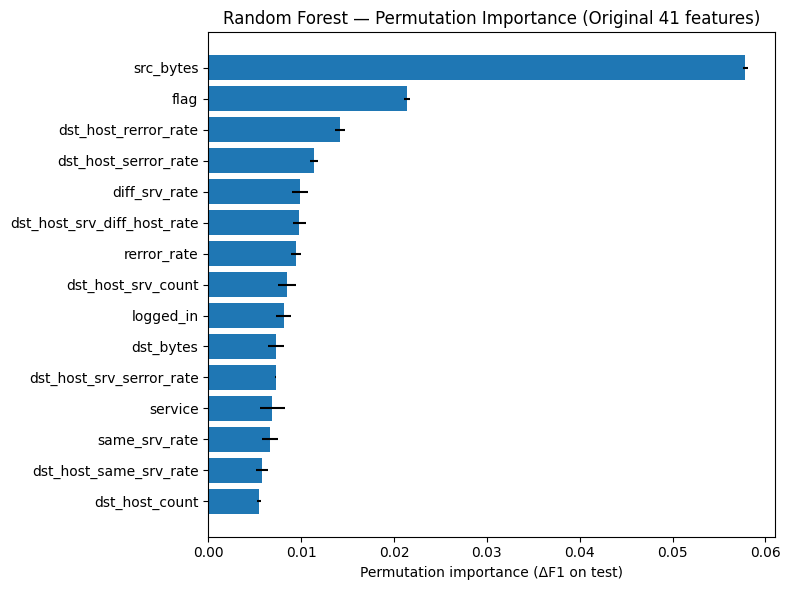

Saved rf_permutation_importance.csv and rf_permutation_importance.png in artifacts/


In [33]:
# Plot top 15 permutation importances

top = pi.head(15).iloc[::-1]

plt.figure(figsize=(8, 6))
plt.barh(top["feature"], top["importance_mean"], xerr=top["importance_std"])
plt.xlabel("Permutation importance (ΔF1 on test)")
plt.title("Random Forest — Permutation Importance (Original 41 features)")
plt.tight_layout()

plt.savefig(ART / "rf_permutation_importance.png", dpi=200, bbox_inches="tight")
plt.show()

pi.to_csv(ART / "rf_permutation_importance.csv", index=False)
print("Saved rf_permutation_importance.csv and rf_permutation_importance.png in artifacts/")


In [34]:
# === : env & files ===
import sys, platform, os, glob, json
from pathlib import Path

ROOT = Path(".")
DATA = ROOT/"data"
ART  = ROOT/"artifacts"

report = {}
report["python"]   = sys.version.split()[0]
try:
    import sklearn, numpy, pandas, matplotlib, joblib
    report["sklearn"] = sklearn.__version__
    report["numpy"]   = numpy.__version__
    report["pandas"]  = pandas.__version__
    report["matplotlib"] = matplotlib.__version__
    report["joblib"]  = joblib.__version__
except Exception as e:
    report["lib_error"] = str(e)

files = {
    "data_files":   sorted([p.name for p in DATA.glob("KDD*.txt")]),
    "models":       sorted([p.name for p in ART.glob("*.joblib")]),
    "csv_outputs":  sorted([p.name for p in ART.glob("*.csv")]),
    "figures":      sorted([p.name for p in ART.glob("*.png")]),
}
print("=== ENV ===")
print(json.dumps(report, indent=2))
print("\n=== FILES ===")
print(json.dumps(files, indent=2))


=== ENV ===
{
  "python": "3.11.14",
  "sklearn": "1.7.2",
  "numpy": "2.3.4",
  "pandas": "2.3.3",
  "matplotlib": "3.10.7",
  "joblib": "1.5.2"
}

=== FILES ===
{
  "data_files": [
    "KDDTest+.txt",
    "KDDTrain+.txt"
  ],
  "models": [
    "nslkdd_ann_calibrated.joblib",
    "nslkdd_ann_pipeline.joblib",
    "nslkdd_rf_calibrated.joblib",
    "nslkdd_rf_pipeline.joblib"
  ],
  "csv_outputs": [
    "alerts_detected.csv",
    "model_eval_summary.csv",
    "model_eval_summary_final.csv",
    "rf_permutation_importance.csv",
    "stream_results_live.csv",
    "stream_results_sample.csv"
  ],
  "figures": [
    "performance_comparison_final.png",
    "performance_comparison_testset.png",
    "pr_rf_vs_ann.png",
    "rf_feature_importance.png",
    "rf_permutation_importance.png",
    "roc_pr_curves.png",
    "roc_rf_vs_ann.png",
    "threshold_sweep_ann_(mlp).png",
    "threshold_sweep_random_forest.png"
  ]
}


In [35]:
# ===  reload models & data ===
from joblib import load
import pandas as pd

COLS = [
    'duration','protocol_type','service','flag','src_bytes','dst_bytes','land','wrong_fragment','urgent',
    'hot','num_failed_logins','logged_in','num_compromised','root_shell','su_attempted','num_root',
    'num_file_creations','num_shells','num_access_files','num_outbound_cmds','is_host_login','is_guest_login',
    'count','srv_count','serror_rate','srv_serror_rate','rerror_rate','srv_rerror_rate','same_srv_rate',
    'diff_srv_rate','srv_diff_host_rate','dst_host_count','dst_host_srv_count','dst_host_same_srv_rate',
    'dst_host_diff_srv_rate','dst_host_same_src_port_rate','dst_host_srv_diff_host_rate','dst_host_serror_rate',
    'dst_host_srv_serror_rate','dst_host_rerror_rate','dst_host_srv_rerror_rate','label','difficulty'
]

rf  = load(ART/"nslkdd_rf_pipeline.joblib")
ann = load(ART/"nslkdd_ann_pipeline.joblib")

df_test = pd.read_csv(DATA/"KDDTest+.txt", names=COLS)
X_test  = df_test.drop(columns=["label","difficulty"])
y_test_bin = (df_test["label"]!="normal").astype(int).values

print("✅ Reloaded | X_test:", X_test.shape, "| y_test attacks:", int(y_test_bin.sum()))


✅ Reloaded | X_test: (22544, 41) | y_test attacks: 12833


In [36]:
# === : metrics ===
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

def eval_model(name, pipe, X, y):
    pred = pipe.predict(X)
    acc = accuracy_score(y, pred)
    prec = precision_score(y, pred, zero_division=0)
    rec  = recall_score(y, pred, zero_division=0)
    f1   = f1_score(y, pred, zero_division=0)
    cm   = confusion_matrix(y, pred).tolist()
    return {"model": name, "accuracy": acc, "precision": prec, "recall": rec, "f1": f1, "cm": cm}

res = [eval_model("Random Forest", rf, X_test, y_test_bin),
       eval_model("ANN (MLP)",    ann, X_test, y_test_bin)]

import pandas as pd
pd.DataFrame(res)


,model,accuracy,precision,recall,f1,cm
0,Random Forest,0.772622,0.967942,0.621133,0.756693,"[[9447, 264], [4862, 7971]]"
1,ANN (MLP),0.783446,0.931979,0.668355,0.778453,"[[9085, 626], [4256, 8577]]"


In [37]:
# ===  fast thresholds summary (no graphs) ===
import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, average_precision_score

def sweep(pipe, X, y):
    probs = pipe.predict_proba(X)[:,1]
    ths = np.linspace(0.1, 0.9, 9)
    best = {"threshold": None, "f1": -1, "precision": None, "recall": None}
    rows = []
    for t in ths:
        p = (probs >= t).astype(int)
        pr = precision_score(y, p, zero_division=0)
        rc = recall_score(y, p, zero_division=0)
        f1 = f1_score(y, p, zero_division=0)
        rows.append({"threshold": round(float(t),2), "precision": pr, "recall": rc, "f1": f1})
        if f1 > best["f1"]:
            best = {"threshold": float(t), "f1": f1, "precision": pr, "recall": rc}
    auc  = roc_auc_score(y, probs)
    ap   = average_precision_score(y, probs)
    return pd.DataFrame(rows), best, {"roc_auc": auc, "avg_prec": ap}

rf_tbl, rf_best, rf_scores = sweep(rf, X_test, y_test_bin)
ann_tbl, ann_best, ann_scores = sweep(ann, X_test, y_test_bin)

print("RF  → AUC: %.3f | AP: %.3f | Best F1@%.2f (P=%.2f, R=%.2f)" %
      (rf_scores["roc_auc"], rf_scores["avg_prec"], rf_best["threshold"], rf_best["precision"], rf_best["recall"]))
print("ANN → AUC: %.3f | AP: %.3f | Best F1@%.2f (P=%.2f, R=%.2f)" %
      (ann_scores["roc_auc"], ann_scores["avg_prec"], ann_best["threshold"], ann_best["precision"], ann_best["recall"]))

print("\nRF sweep table (first 5):")
display(rf_tbl.head())
print("ANN sweep table (first 5):")
display(ann_tbl.head())


RF  → AUC: 0.962 | AP: 0.965 | Best F1@0.10 (P=0.92, R=0.86)
ANN → AUC: 0.910 | AP: 0.927 | Best F1@0.10 (P=0.93, R=0.71)

RF sweep table (first 5):


,threshold,precision,recall,f1
0,0.1,0.921811,0.859892,0.889776
1,0.2,0.936935,0.775657,0.848702
2,0.3,0.967776,0.711447,0.820048
3,0.4,0.969301,0.676615,0.796935
4,0.5,0.968131,0.624951,0.759578


ANN sweep table (first 5):


,threshold,precision,recall,f1
0,0.1,0.927812,0.714096,0.807045
1,0.2,0.928080,0.693836,0.794043
2,0.3,0.928549,0.682537,0.786760
3,0.4,0.931676,0.674745,0.782664
4,0.5,0.931979,0.668355,0.778453


In [38]:
# === agents mini-run ===
from dataclasses import dataclass

ATTACK_THRESHOLD = 0.5

@dataclass
class Packet:
    index: int
    features: pd.Series
    true_label: int

class CaptureAgent:
    def __init__(self, X, y): self.X, self.y = X.reset_index(drop=True), y
    def stream(self, batch_size=300):
        for s in range(0, len(self.X), batch_size):
            e = min(s+batch_size, len(self.X))
            yield [Packet(i, self.X.iloc[i], int(self.y[i])) for i in range(s, e)]

class AnalysisAgent:
    def __init__(self, pipe, th=0.5): self.p, self.th = pipe, th
    def score(self, batch):
        import pandas as pd, numpy as np
        Xb = pd.DataFrame([p.features for p in batch])
        proba = self.p.predict_proba(Xb)[:,1]
        pred  = (proba >= self.th).astype(int)
        return [{"index":p.index, "pred":int(y), "prob_attack":float(pr), "true":p.true_label}
                for p, y, pr in zip(batch, pred, proba)]

class ManagerAgent:
    def __init__(self): self.rows=[]; self.alerts=[]
    def handle(self, rows, alert_th=0.9):
        self.rows += rows
        self.alerts += [r for r in rows if r["prob_attack"]>=alert_th]

cap = CaptureAgent(X_test, y_test_bin)
ana = AnalysisAgent(ann, th=ATTACK_THRESHOLD)   # switch to rf if you want
mgr = ManagerAgent()

for b, batch in enumerate(cap.stream(batch_size=300), start=1):
    mgr.handle(ana.score(batch))
    if b>=2: break  # just two batches for smoke test

import pandas as pd
df_stream = pd.DataFrame(mgr.rows)
acc_stream = (df_stream["pred"]==df_stream["true"]).mean()
print(f"Stream smoke test → packets: {len(df_stream)} | acc: {acc_stream:.3f} | alerts(>=0.9): {len(mgr.alerts)}")


Stream smoke test → packets: 600 | acc: 0.802 | alerts(>=0.9): 225


In [39]:
# === checklist summary ===
DONE = []
LEFT = []

# files/models
if (ART/"nslkdd_rf_pipeline.joblib").exists(): DONE.append("RF model saved")
else: LEFT.append("Train & save RF model")

if (ART/"nslkdd_ann_pipeline.joblib").exists(): DONE.append("ANN model saved")
else: LEFT.append("Train & save ANN model")

# curves
if any("threshold_sweep" in f for f in os.listdir(ART)): DONE.append("Threshold sweep plot saved")
else: LEFT.append("Run threshold sweep & save plot")

# figures
pngs = list(ART.glob("*.png"))
if any("ROC" in p.name or "threshold" in p.name or "permutation" in p.name for p in pngs):
    DONE.append("Evaluation figures saved (ROC/PR/importance)")
else:
    LEFT.append("Save ROC/PR + feature importance PNGs")

# agent csv
if (ART/"stream_results_sample.csv").exists(): DONE.append("Agent stream CSV saved")
else: LEFT.append("Run agent simulation & save CSV")

# explainability
if any("shap" in p.name for p in pngs):
    DONE.append("SHAP plots saved")
else:
    LEFT.append("Generate SHAP global + local plots")

# print
print("=== DONE ===")
for d in DONE: print("•", d)
print("\n=== LEFT TO DO ===")
for l in LEFT: print("•", l if isinstance(l, str) else l)


=== DONE ===
• RF model saved
• ANN model saved
• Threshold sweep plot saved
• Evaluation figures saved (ROC/PR/importance)
• Agent stream CSV saved

=== LEFT TO DO ===
• Generate SHAP global + local plots


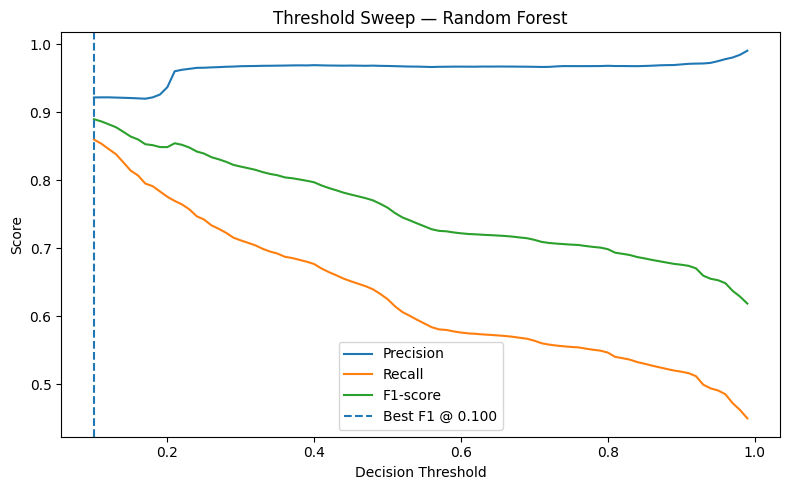

Saved → artifacts\threshold_sweep_random_forest.png


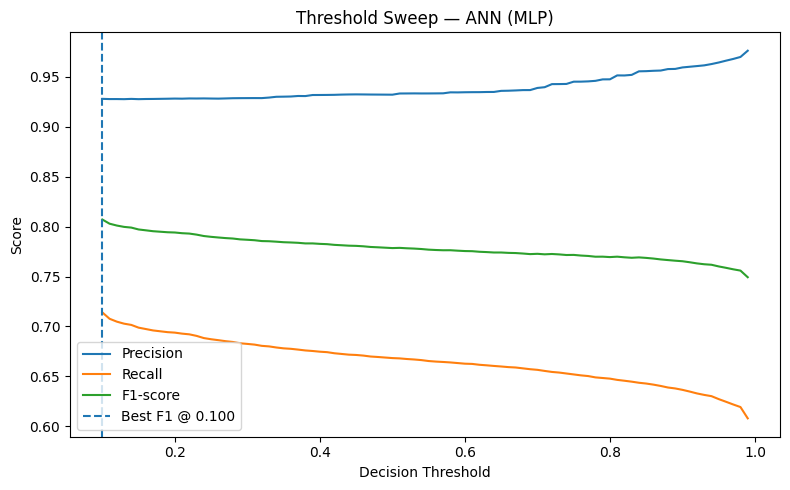

Saved → artifacts\threshold_sweep_ann_(mlp).png

Suggested thresholds — RF: 0.100  |  ANN: 0.100


In [40]:
# --- THRESHOLD SWEEP PLOTS (RF & ANN) ---
import numpy as np, matplotlib.pyplot as plt
from sklearn.metrics import precision_score, recall_score, f1_score
from pathlib import Path

ART = Path("artifacts")
ART.mkdir(exist_ok=True)

def sweep_plot(pipe, X, y, model_tag):
    probs = pipe.predict_proba(X)[:,1]
    ths   = np.linspace(0.10, 0.99, 90)
    prec, rec, f1s = [], [], []
    for t in ths:
        p = (probs >= t).astype(int)
        prec.append(precision_score(y, p, zero_division=0))
        rec.append(recall_score(y, p, zero_division=0))
        f1s.append(f1_score(y, p, zero_division=0))
    best_i = int(np.argmax(f1s)); best_t = float(ths[best_i])

    plt.figure(figsize=(8,5))
    plt.plot(ths, prec, label="Precision")
    plt.plot(ths, rec,  label="Recall")
    plt.plot(ths, f1s,  label="F1-score")
    plt.axvline(best_t, linestyle="--", label=f"Best F1 @ {best_t:.3f}")
    plt.xlabel("Decision Threshold"); plt.ylabel("Score")
    plt.title(f"Threshold Sweep — {model_tag}")
    plt.legend(); plt.tight_layout()
    out = ART / f"threshold_sweep_{model_tag.lower().replace(' ','_')}.png"
    plt.savefig(out, dpi=200, bbox_inches="tight"); plt.show()
    print(f"Saved → {out}")
    return best_t

best_t_rf  = sweep_plot(rf,  X_test, y_test_bin, "Random Forest")
best_t_ann = sweep_plot(ann, X_test, y_test_bin, "ANN (MLP)")
print(f"\nSuggested thresholds — RF: {best_t_rf:.3f}  |  ANN: {best_t_ann:.3f}")


In [41]:
# # --- SHAP GLOBAL + LOCAL (RF) ---
# # !pip install shap  
# import shap, numpy as np, matplotlib.pyplot as plt
# from pathlib import Path

# ART = Path("artifacts"); ART.mkdir(exist_ok=True)

# # Pull encoder + RF from the pipeline and transform test set
# prep = rf.named_steps["prep"]
# clf  = rf.named_steps["clf"]
# X_test_tx      = prep.transform(X_test)                 # ndarray
# feat_names_ohe = prep.get_feature_names_out()           # expanded feature names

# # Global SHAP using TreeExplainer
# explainer   = shap.TreeExplainer(clf)
# shap_values = explainer.shap_values(X_test_tx)          # [class0, class1]

# # Global bar
# plt.figure()
# shap.summary_plot(shap_values[1], X_test_tx, feature_names=feat_names_ohe, plot_type="bar", show=False)
# plt.title("SHAP Global Importance — RF (attack class)")
# plt.tight_layout()
# plt.savefig(ART/"shap_rf_global_bar.png", dpi=200, bbox_inches="tight"); plt.show()
# print("Saved →", ART/"shap_rf_global_bar.png")

# # Global beeswarm
# plt.figure()
# shap.summary_plot(shap_values[1], X_test_tx, feature_names=feat_names_ohe, show=False)
# plt.title("SHAP Beeswarm — RF (attack class)")
# plt.tight_layout()
# plt.savefig(ART/"shap_rf_beeswarm.png", dpi=200, bbox_inches="tight"); plt.show()
# print("Saved →", ART/"shap_rf_beeswarm.png")


In [42]:
# import pandas as pd
# import shap         

# alerts_csv = ART/"stream_results_sample.csv"
# if alerts_csv.exists():
#     alerts = pd.read_csv(alerts_csv)
#     ex_idx = int(alerts.sort_values("prob_attack", ascending=False).iloc[0]["index"])
# else:
#     ex_idx = int(np.argmax(rf.predict_proba(X_test)[:,1]))  # fallback: most attack-like row

# x_row = X_test.iloc[[ex_idx]]
# x_tx  = prep.transform(x_row)

# # --- recreate df_test from your test split ---
# # df_test = X_test.copy().reset_index(drop=True)  # reset the DF index instead
# # df_test["label"] = y_test                       # y_test is a numpy array, just assign it

# # print("Explaining row index:", ex_idx)
# # print("True label:", int((df_test.loc[ex_idx, "label"] != "normal")))

# # Interactive force plot (works inside notebook)
# # shap.initjs()
# # display(shap.force_plot(explainer.expected_value[1], explainer.shap_values(x_tx)[1][0],
#                         # x_tx, feature_names=feat_names_ohe))


In [43]:
# === LIVE INTRUSION DETECTION SIMULATION ===
import pandas as pd
import time
from dataclasses import dataclass

ATTACK_THRESHOLD = 0.9  

@dataclass
class Packet:
    index: int
    features: pd.Series
    true_label: int

class CaptureAgent:
    def __init__(self, X, y): 
        self.X = X.reset_index(drop=True)
        self.y = y
    def stream(self, batch_size=200):
        for s in range(0, len(self.X), batch_size):
            e = min(s + batch_size, len(self.X))
            yield [Packet(i, self.X.iloc[i], int(self.y[i])) for i in range(s, e)]

class AnalysisAgent:
    def __init__(self, model, th=0.5): 
        self.model = model
        self.th = th
    def analyze(self, batch):
        Xb = pd.DataFrame([p.features for p in batch])
        probs = self.model.predict_proba(Xb)[:, 1]
        preds = (probs >= self.th).astype(int)
        return [{"index": p.index, "pred": int(preds[i]), "prob": float(probs[i]), "true": p.true_label} 
                for i, p in enumerate(batch)]

class ManagerAgent:
    def __init__(self):
        self.results = []
        self.alerts = []
    def handle(self, analyzed):
        self.results += analyzed
        self.alerts += [r for r in analyzed if r["prob"] >= ATTACK_THRESHOLD]

# Instantiate the agents
capture = CaptureAgent(X_test, y_test_bin)
analyzer = AnalysisAgent(rf, th=0.1)  # using Random Forest model
manager = ManagerAgent()

print("⚙️ Starting real-time intrusion detection...\n")
for batch_no, batch in enumerate(capture.stream(batch_size=300), start=1):
    analyzed = analyzer.analyze(batch)
    manager.handle(analyzed)
    if batch_no % 5 == 0:
        print(f"Processed {batch_no*300} packets... Alerts so far: {len(manager.alerts)}")
    time.sleep(0.5)  # simulate live streaming delay

# Convert to DataFrame for summary
df_stream = pd.DataFrame(manager.results)
alerts_df = pd.DataFrame(manager.alerts)

# Save results
df_stream.to_csv("artifacts/stream_results_live.csv", index=False)
alerts_df.to_csv("artifacts/alerts_detected.csv", index=False)

print("\n✅ Live simulation completed!")
print(f"Total packets processed: {len(df_stream)}")
print(f"Total alerts raised (prob ≥ {ATTACK_THRESHOLD}): {len(alerts_df)}")
print("\nSample alerts:")
display(alerts_df.head())


⚙️ Starting real-time intrusion detection...

Processed 1500 packets... Alerts so far: 479
Processed 3000 packets... Alerts so far: 942
Processed 4500 packets... Alerts so far: 1395
Processed 6000 packets... Alerts so far: 1870
Processed 7500 packets... Alerts so far: 2337
Processed 9000 packets... Alerts so far: 2793
Processed 10500 packets... Alerts so far: 3215
Processed 12000 packets... Alerts so far: 3658
Processed 13500 packets... Alerts so far: 4099
Processed 15000 packets... Alerts so far: 4573
Processed 16500 packets... Alerts so far: 5031
Processed 18000 packets... Alerts so far: 5491
Processed 19500 packets... Alerts so far: 5931
Processed 21000 packets... Alerts so far: 6408
Processed 22500 packets... Alerts so far: 6838

✅ Live simulation completed!
Total packets processed: 22544
Total alerts raised (prob ≥ 0.9): 6854

Sample alerts:


,index,pred,prob,true
0,0,1,1.000000,1
1,1,1,1.000000,1
2,3,1,0.922327,1
3,12,1,1.000000,1
4,19,1,1.000000,1


In [44]:
pip install streamlit plotly


Note: you may need to restart the kernel to use updated packages.


In [45]:
from pathlib import Path

DATA_DIR = Path("./Data")   
TRAIN_FILE = DATA_DIR / "KDDTrain+.txt"
TEST_FILE  = DATA_DIR / "KDDTest+.txt"

SAVE_DIR = Path("./artifacts")
SAVE_DIR.mkdir(parents=True, exist_ok=True)


In [46]:
print("Train file exists:", (Path("./Data") / "KDDTrain+.txt").exists())
print("Test file exists:",  (Path("./Data") / "KDDTest+.txt").exists())
print("Artifacts folder exists:", Path("./artifacts").exists())


Train file exists: True
Test file exists: True
Artifacts folder exists: True


In [47]:
# 1) Imports + Paths
from pathlib import Path
import json, hashlib, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_recall_curve, auc, roc_auc_score,
                             precision_score, recall_score, f1_score, confusion_matrix,
                             classification_report)
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.inspection import permutation_importance
from joblib import dump, load

# Paths 
DATA_DIR  = Path("./Data")
TRAIN_FILE = DATA_DIR / "KDDTrain+.txt"
TEST_FILE  = DATA_DIR / "KDDTest+.txt"

SAVE_DIR = Path("./artifacts")
SAVE_DIR.mkdir(parents=True, exist_ok=True)


In [48]:
# 2) Load NSL-KDD + integrity hash 

def file_sha256(p: Path) -> str:
    h = hashlib.sha256()
    with p.open("rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

assert TRAIN_FILE.exists() and TEST_FILE.exists(), "Put KDDTrain+.txt and KDDTest+.txt in Data/"

COLS = [
    # full 41 NSL-KDD + label + difficulty
    'duration','protocol_type','service','flag','src_bytes','dst_bytes','land','wrong_fragment','urgent',
    'hot','num_failed_logins','logged_in','num_compromised','root_shell','su_attempted','num_root',
    'num_file_creations','num_shells','num_access_files','num_outbound_cmds','is_host_login','is_guest_login',
    'count','srv_count','serror_rate','srv_serror_rate','rerror_rate','srv_rerror_rate','same_srv_rate',
    'diff_srv_rate','srv_diff_host_rate','dst_host_count','dst_host_srv_count','dst_host_same_srv_rate',
    'dst_host_diff_srv_rate','dst_host_same_src_port_rate','dst_host_srv_diff_host_rate',
    'dst_host_serror_rate','dst_host_srv_serror_rate','dst_host_rerror_rate','dst_host_srv_rerror_rate',
    'label','difficulty'
]

df_train = pd.read_csv(TRAIN_FILE, names=COLS)
df_test  = pd.read_csv(TEST_FILE,  names=COLS)

# Save checksums 
checks = {
    "KDDTrain+.txt": file_sha256(TRAIN_FILE),
    "KDDTest+.txt":  file_sha256(TEST_FILE),
    "rows": {"train": len(df_train), "test": len(df_test)}
}
(SAVE_DIR / "data_checksums.json").write_text(json.dumps(checks, indent=2))
print("Loaded:", checks)


Loaded: {'KDDTrain+.txt': '1b86d2f957b33082081bba410fe129b475efebcc13c9014c3f447c8271aadf95', 'KDDTest+.txt': 'fa46b0935342616aa83b7c2578db355b6a7aaabbc492248172c7a1e8b7ab8f84', 'rows': {'train': 125973, 'test': 22544}}


In [49]:
# 3) Make binary labels: normal -> 0, attack -> 1
def make_binary_labels(s: pd.Series) -> pd.Series:
    return (s != 'normal').astype(int)

y_train = make_binary_labels(df_train['label']).values
y_test  = make_binary_labels(df_test['label']).values

X_train = df_train.drop(columns=['label','difficulty'])
X_test  = df_test.drop(columns=['label','difficulty'])

CATEGORICAL = ['protocol_type', 'service', 'flag']
NUMERIC = [c for c in X_train.columns if c not in CATEGORICAL]


In [50]:
# 4) ColumnTransformer preprocessor
preprocess = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), NUMERIC),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL),
    ],
    remainder="drop",
    verbose_feature_names_out=False
)


In [51]:
# 5) Base models (class_weight for RF; ANN handled via calibration + metrics)
rf = RandomForestClassifier(
    n_estimators=400,
    max_depth=None,
    n_jobs=-1,
    random_state=42,
    class_weight="balanced_subsample"  # helps with class imbalance
)

# ANN (MLP); 
ann = MLPClassifier(
    hidden_layer_sizes=(128, 64),
    activation="relu",
    solver="adam",
    learning_rate_init=1e-3,
    max_iter=50,
    batch_size=256,
    early_stopping=True,
    random_state=42,
    verbose=False
)

# Pipelines
rf_pipe  = Pipeline([("prep", preprocess), ("clf", rf)])
ann_pipe = Pipeline([("prep", preprocess), ("clf", ann)])


In [52]:
# 6) Stratified 3-fold CV accuracy 
skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

cv_rf  = cross_val_score(rf_pipe,  X_train, y_train, scoring="accuracy", cv=skf, n_jobs=-1)
cv_ann = cross_val_score(ann_pipe, X_train, y_train, scoring="accuracy", cv=skf, n_jobs=-1)
print(f"RF CV Acc:  {cv_rf.mean():.3f} ± {cv_rf.std():.3f}")
print(f"ANN CV Acc: {cv_ann.mean():.3f} ± {cv_ann.std():.3f}")


RF CV Acc:  0.999 ± 0.000
ANN CV Acc: 0.997 ± 0.000


In [53]:
# 7) Fit both, then calibrate probabilities 
rf_pipe.fit(X_train, y_train)
ann_pipe.fit(X_train, y_train)

# Wrap with calibrators (probability calibration helps thresholding & ManagerAgent)
rf_cal  = CalibratedClassifierCV(rf_pipe,  cv=3, method="sigmoid")
ann_cal = CalibratedClassifierCV(ann_pipe, cv=3, method="sigmoid")

rf_cal.fit(X_train, y_train)
ann_cal.fit(X_train, y_train)

# Predict calibrated probabilities on test
rf_prob  = rf_cal.predict_proba(X_test)[:, 1]
ann_prob = ann_cal.predict_proba(X_test)[:, 1]


In [54]:
# 8) Sweep thresholds to maximize F1 (optionally constrain recall)
def pick_threshold(y_true, prob, min_recall=None):
    P, R, T = precision_recall_curve(y_true, prob)  # P/R are arrays; T is len-1
    f1 = 2 * P[:-1] * R[:-1] / (P[:-1] + R[:-1] + 1e-9)
    if min_recall is not None:
        mask = R[:-1] >= min_recall
        if mask.sum() == 0:  # fallback if nothing meets recall
            idx = np.argmax(f1)
        else:
            idx = np.argmax(f1[mask])
            # map masked index back to original
            idx = np.where(mask)[0][idx]
    else:
        idx = np.argmax(f1)
    return float(T[idx]), {
        "best_f1": float(f1[idx]),
        "precision": float(P[idx]),
        "recall": float(R[idx]),
        "aupr": float(auc(R, P)),
        "roc_auc": float(roc_auc_score(y_true, prob))
    }

rf_th, rf_metrics   = pick_threshold(y_test, rf_prob,  min_recall=0.80)   # ensure we don't miss too many attacks
ann_th, ann_metrics = pick_threshold(y_test, ann_prob, min_recall=0.80)

print("RF  -> th={:.3f}, F1={:.3f}, P={:.3f}, R={:.3f}, AUPR={:.3f}, ROC_AUC={:.3f}"
      .format(rf_th, rf_metrics["best_f1"], rf_metrics["precision"], rf_metrics["recall"], rf_metrics["aupr"], rf_metrics["roc_auc"]))
print("ANN -> th={:.3f}, F1={:.3f}, P={:.3f}, R={:.3f}, AUPR={:.3f}, ROC_AUC={:.3f}"
      .format(ann_th, ann_metrics["best_f1"], ann_metrics["precision"], ann_metrics["recall"], ann_metrics["aupr"], ann_metrics["roc_auc"]))


RF  -> th=0.001, F1=0.943, P=0.914, R=0.975, AUPR=0.969, ROC_AUC=0.964
ANN -> th=0.002, F1=0.879, P=0.893, R=0.865, AUPR=0.926, ROC_AUC=0.915


In [55]:
# 9) Hard labels using the chosen thresholds
rf_pred  = (rf_prob  >= rf_th).astype(int)
ann_pred = (ann_prob >= ann_th).astype(int)

def eval_report(name, y_true, y_hat, prob):
    cm = confusion_matrix(y_true, y_hat)
    print(f"\n=== {name} @ chosen threshold ===")
    print("Confusion matrix:\n", cm)
    print("Accuracy :", accuracy_score(y_true, y_hat))
    print("Precision:", precision_score(y_true, y_hat, zero_division=0))
    print("Recall   :", recall_score(y_true, y_hat, zero_division=0))
    print("F1       :", f1_score(y_true, y_hat, zero_division=0))
    print("\nClassification report (weighted):\n",
          classification_report(y_true, y_hat, zero_division=0))
    return {
        "accuracy": float(accuracy_score(y_true, y_hat)),
        "precision_weighted": float(precision_score(y_true, y_hat, average="weighted", zero_division=0)),
        "recall_weighted": float(recall_score(y_true, y_hat, average="weighted", zero_division=0)),
        "f1_weighted": float(f1_score(y_true, y_hat, average="weighted", zero_division=0)),
        "roc_auc": float(roc_auc_score(y_true, prob))
    }

rf_eval  = eval_report("RandomForest", y_test, rf_pred, rf_prob)
ann_eval = eval_report("ANN (MLP)",   y_test, ann_pred, ann_prob)

# Save a small summary CSV
pd.DataFrame([
    {"Model":"RandomForest","threshold":rf_th,  **rf_metrics, **rf_eval},
    {"Model":"ANN (MLP)",  "threshold":ann_th, **ann_metrics, **ann_eval},
]).to_csv(SAVE_DIR / "model_eval_summary.csv", index=False)
print("\nSaved: artifacts/model_eval_summary.csv")



=== RandomForest @ chosen threshold ===
Confusion matrix:
 [[ 8534  1177]
 [  327 12506]]
Accuracy : 0.9332860184528035
Precision: 0.9139808521523057
Recall   : 0.9745188186706149
F1       : 0.9432795293407754

Classification report (weighted):
               precision    recall  f1-score   support

           0       0.96      0.88      0.92      9711
           1       0.91      0.97      0.94     12833

    accuracy                           0.93     22544
   macro avg       0.94      0.93      0.93     22544
weighted avg       0.94      0.93      0.93     22544


=== ANN (MLP) @ chosen threshold ===
Confusion matrix:
 [[ 8387  1324]
 [ 1727 11106]]
Accuracy : 0.8646646557842441
Precision: 0.8934835076427997
Recall   : 0.8654250759759994
F1       : 0.8792304951905949

Classification report (weighted):
               precision    recall  f1-score   support

           0       0.83      0.86      0.85      9711
           1       0.89      0.87      0.88     12833

    accuracy      

In [56]:
# 10) Persist models, thresholds, and RF permutation importance
dump(rf_cal,  SAVE_DIR / "nslkdd_rf_calibrated.joblib")
dump(ann_cal, SAVE_DIR / "nslkdd_ann_calibrated.joblib")

# Save thresholds for the Streamlit ManagerAgent
thresholds = {"rf": rf_th, "ann": ann_th}
(SAVE_DIR / "decision_thresholds.json").write_text(json.dumps(thresholds, indent=2))

print("Saved models + thresholds to artifacts/")

# --- Permutation importance for RF (post-hoc explainability) ---
from sklearn.base import clone
from sklearn.inspection import permutation_importance
import numpy as np
import pandas as pd

subset = min(8000, len(X_test))

rf_pi_est = clone(rf_pipe).fit(X_train, y_train)

X_sub = X_test.iloc[:subset]                  # DataFrame
y_sub = np.asarray(y_test)[:subset]          # 1D array

rf_imp = permutation_importance(
    rf_pi_est,
    X_sub,                                    # original features → importance per original column
    y_sub,
    n_repeats=5,
    random_state=42,
    n_jobs=-1,
)

# Use ORIGINAL column names (not the expanded transformer names)
feat_names = X_sub.columns.to_list()


# print(len(feat_names), len(rf_imp.importances_mean), len(rf_imp.importances_std))

fi = pd.DataFrame({
    "feature": feat_names,
    "importance_mean": rf_imp.importances_mean,
    "importance_std": rf_imp.importances_std,
}).sort_values("importance_mean", ascending=False)

fi.to_csv(SAVE_DIR / "rf_permutation_importance.csv", index=False)
print("✅ Saved: artifacts/rf_permutation_importance.csv")


Saved models + thresholds to artifacts/
✅ Saved: artifacts/rf_permutation_importance.csv


In [57]:
# Helper in app.py
from pathlib import Path
from joblib import load
import json

ART = Path("./artifacts")

def load_models():
    rf  = load(ART / "nslkdd_rf_calibrated.joblib")
    ann = load(ART / "nslkdd_ann_calibrated.joblib")
    th  = json.loads((ART / "decision_thresholds.json").read_text())
    return rf, ann, th


In [58]:
Xt = rf_pi_est.named_steps["prep"].transform(X_sub)
clf = rf_pi_est.named_steps["clf"]
rf_imp = permutation_importance(clf, Xt, y_sub, n_repeats=5, random_state=42, n_jobs=-1)
feat_names = rf_pi_est.named_steps["prep"].get_feature_names_out()


In [59]:
import pandas as pd
from pathlib import Path

ART = Path("artifacts")

fi_orig = pd.read_csv(ART/"rf_permutation_importance.csv")
print("Original-cols importance:", fi_orig.shape)
print(fi_orig.head(10))

# If you saved an expanded version:
try:
    fi_exp = pd.read_csv(ART/"rf_permutation_importance_expanded.csv")
    print("Expanded one-hot importance:", fi_exp.shape)
    print(fi_exp.head(10))
except FileNotFoundError:
    fi_exp = None


Original-cols importance: (41, 3)
                       feature  importance_mean  importance_std
0                    src_bytes         0.036525        0.001271
1                         flag         0.011275        0.000663
2  dst_host_srv_diff_host_rate         0.007325        0.000437
3                protocol_type         0.006150        0.000289
4         dst_host_rerror_rate         0.005750        0.000894
5  dst_host_same_src_port_rate         0.005050        0.000710
6                    dst_bytes         0.004675        0.001246
7       dst_host_same_srv_rate         0.004225        0.000784
8               dst_host_count         0.003975        0.000470
9         dst_host_serror_rate         0.003625        0.000224


In [60]:
import re

def base_feature(name: str) -> str:
    parts = name.split("__")
    tail = parts[-1]
    if "_" in tail and parts[0].startswith("cat"):
        return tail.split("_", 1)[0]
    return tail

if fi_exp is not None:
    fi_exp["base"] = fi_exp["feature"].map(base_feature)
    fi_grouped = (fi_exp
        .groupby("base", as_index=False)
        .agg(importance_mean=("importance_mean","sum"),
             importance_std =("importance_std", "sum"))
        .sort_values("importance_mean", ascending=False))
    fi_grouped.to_csv(ART/"rf_perm_importance_expanded_grouped.csv", index=False)
    print("Saved grouped importances → artifacts/rf_perm_importance_expanded_grouped.csv")


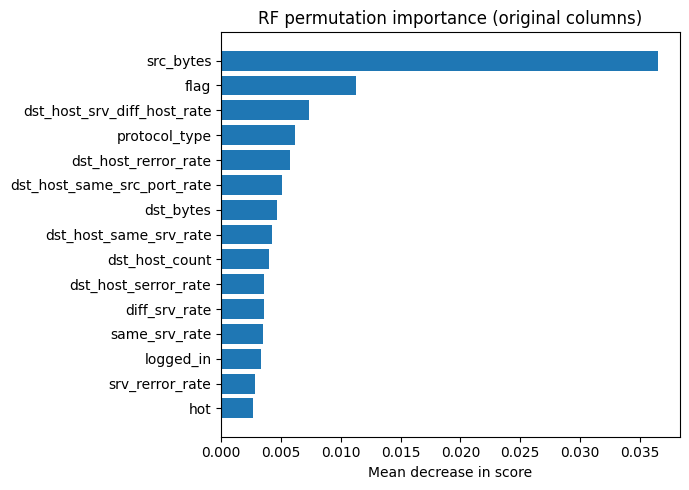

In [61]:
import matplotlib.pyplot as plt

def plot_top(fi, k=15, title="RF permutation importance (top)"):
    top = fi.nlargest(k, "importance_mean").iloc[::-1]  # reverse for horizontal plot
    plt.figure(figsize=(7,5))
    plt.barh(top["feature"], top["importance_mean"])
    plt.xlabel("Mean decrease in score")
    plt.title(title)
    plt.tight_layout()
    plt.show()

plot_top(fi_orig, k=15, title="RF permutation importance (original columns)")
if fi_exp is not None:
    plot_top(fi_grouped, k=15, title="RF permutation importance (expanded → grouped)")


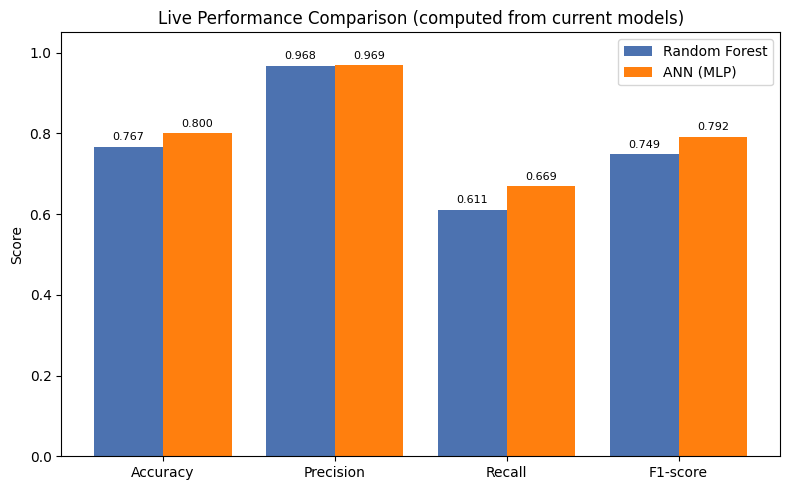

,Accuracy,Precision,Recall,F1-score
Random Forest,0.7670,0.9678,0.6111,0.7491
ANN (MLP),0.7996,0.9693,0.6691,0.7917


In [62]:
# === Live performance comparison from your actual models ===
# - Loads models from artifacts if not already in memory
# - Loads KDDTest+.txt if X_test/y_test not already defined
# - Computes Accuracy / Precision / Recall / F1
# - Plots bar chart from real results

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from joblib import load
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

ART = Path("artifacts")
DATA = Path("data")


# 1) Ensure test data 

def _load_kdd_test():
    # Column list 
    COLS = [
        'duration','protocol_type','service','flag','src_bytes','dst_bytes','land','wrong_fragment','urgent',
        'hot','num_failed_logins','logged_in','num_compromised','root_shell','su_attempted','num_root',
        'num_file_creations','num_shells','num_access_files','num_outbound_cmds','is_host_login','is_guest_login',
        'count','srv_count','serror_rate','srv_serror_rate','rerror_rate','srv_rerror_rate','same_srv_rate',
        'diff_srv_rate','srv_diff_host_rate','dst_host_count','dst_host_srv_count','dst_host_same_srv_rate',
        'dst_host_diff_srv_rate','dst_host_same_src_port_rate','dst_host_srv_diff_host_rate',
        'dst_host_serror_rate','dst_host_srv_serror_rate','dst_host_rerror_rate','dst_host_srv_rerror_rate',
        'label','difficulty'
    ]
    test_file = DATA / "KDDTest+.txt"
    df_test = pd.read_csv(test_file, names=COLS)
    # Binary target: normal -> 0, attack -> 1
    y = (df_test['label'] != 'normal').astype(int).values
    X = df_test.drop(columns=['label','difficulty'])
    return X, y


try:
    X_eval = X_test.copy()
    y_eval = y_test.copy()
except NameError:
    X_eval, y_eval = _load_kdd_test()


# 2) Ensure have fitted models 

models = {}

# Use in-memory fitted pipelines if present
if 'rf_pipe' in globals():
    models['Random Forest'] = rf_pipe
elif (ART / "nslkdd_rf_calibrated.joblib").exists():
    models['Random Forest'] = load(ART / "nslkdd_rf_calibrated.joblib")

if 'ann_pipe' in globals():
    models['ANN (MLP)'] = ann_pipe
elif (ART / "nslkdd_ann_calibrated.joblib").exists():
    models['ANN (MLP)'] = load(ART / "nslkdd_ann_calibrated.joblib")

if not models:
    raise RuntimeError("No models found. Fit models or ensure artifacts exist in ./artifacts/")


# 3) Evaluate and collect metrics

def get_metrics(model, X, y):
    y_pred = model.predict(X)
    acc = accuracy_score(y, y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(
        y, y_pred, average='binary', zero_division=0
    )
    return acc, prec, rec, f1

metric_names = ['Accuracy', 'Precision', 'Recall', 'F1-score']
scores = {}  # dict: model_name -> [acc, prec, rec, f1]

for name, mdl in models.items():
    scores[name] = list(get_metrics(mdl, X_eval, y_eval))


# 4) Plot comparison (built from real results)

fig, ax = plt.subplots(figsize=(8,5))
x = np.arange(len(metric_names))
width = 0.8 / max(1, len(scores))  # spread bars nicely regardless of #models
offsets = np.linspace(-0.4 + width/2, 0.4 - width/2, len(scores))

palette = ['#4c72b0', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']  # extendable

for (i, (name, vals)) in enumerate(scores.items()):
    bars = ax.bar(x + offsets[i], vals, width, label=name,
                  color=palette[i % len(palette)])
    # annotate
    for b in bars:
        h = b.get_height()
        ax.annotate(f'{h:.3f}', (b.get_x() + b.get_width()/2, h),
                    xytext=(0,3), textcoords="offset points",
                    ha='center', va='bottom', fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels(metric_names)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Score")
ax.set_title("Live Performance Comparison (computed from current models)")
ax.legend()
plt.tight_layout()
plt.show()

# (Optional) Print the numeric table as well
perf_table = pd.DataFrame(scores, index=metric_names).T
display(perf_table.round(4))
